# 04 — Image Preprocessing and Augmentation

This notebook demonstrates the preprocessing pipeline for the Sorghum cultivar dataset.

**Scope:** preprocessing verification only. No model is trained here.

**Contents:**
1. Manifest verification
2. Class-to-index mapping
3. Original image
4. Preprocessed image (val/test transform)
5. Augmented examples (train transform)
6. Batch sanity checks (shape, dtype, normalization, labels)
7. Determinism check for val/test

In [8]:
from pathlib import Path
import sys

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists():
    REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT / "src"))

In [15]:
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image

REPO_ROOT = Path(r"C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water").resolve()
sys.path.insert(0, str(REPO_ROOT / "src"))

from preprocessing import (
    get_train_transform,
    get_val_transform,
    get_test_transform,
    IMAGE_SIZE,
    IMAGENET_MEAN,
    IMAGENET_STD,
)
from dataset import SorghumDataset, build_class_to_idx, load_class_to_idx, make_loader

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

IMAGE_DIR = REPO_ROOT.parent / "Dataset"
RESULTS = REPO_ROOT / "results"

print(f"Image directory : {IMAGE_DIR}")
print(f"Results directory: {RESULTS}")

Image directory : C:\Users\nihar\OneDrive\Desktop\Water To Pixels\Dataset
Results directory: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\results


## 1. Manifest Verification

In [16]:
train_df = pd.read_csv(RESULTS /"train.csv")
val_df   = pd.read_csv(RESULTS /"validation.csv")
test_df  = pd.read_csv(RESULTS /"test.csv")

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    missing = sum(1 for f in df["image"] if not (IMAGE_DIR / f).exists())
    print(f"{name:12s}: {len(df):5d} rows | {missing} missing images | "
          f"{df['cultivar'].nunique()} cultivars")

# Overlap checks
assert len(set(train_df["image"]) & set(val_df["image"]))  == 0, "train/val overlap!"
assert len(set(train_df["image"]) & set(test_df["image"])) == 0, "train/test overlap!"
assert len(set(val_df["image"])   & set(test_df["image"])) == 0, "val/test overlap!"
print("\nNo cross-split overlap detected.")

train       :  4000 rows | 0 missing images | 100 cultivars
validation  :   500 rows | 0 missing images | 100 cultivars
test        :   500 rows | 0 missing images | 100 cultivars

No cross-split overlap detected.


## 2. Class-to-Index Mapping

In [17]:
class_to_idx = load_class_to_idx(RESULTS / "class_to_index.json")
print(f"Number of classes: {len(class_to_idx)}")
print("First 5 entries:", dict(list(class_to_idx.items())[:5]))
print("Last  5 entries:", dict(list(class_to_idx.items())[-5:]))

Number of classes: 100
First 5 entries: {'PI_144134': 0, 'PI_145619': 1, 'PI_145626': 2, 'PI_145633': 3, 'PI_146890': 4}
Last  5 entries: {'PI_329351': 95, 'PI_35038': 96, 'PI_52606': 97, 'PI_63715': 98, 'PI_92270': 99}


## 3. Original Image

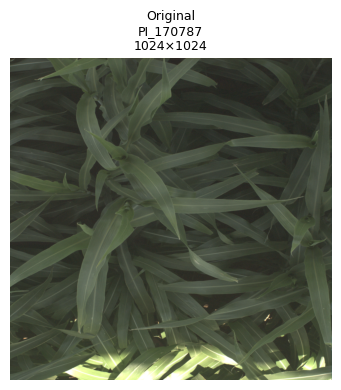

In [18]:
sample_row = train_df.sample(1, random_state=SEED).iloc[0]
orig_img = Image.open(IMAGE_DIR / sample_row["image"]).convert("RGB")

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(orig_img)
ax.set_title(f"Original\n{sample_row['cultivar']}\n{orig_img.size[0]}×{orig_img.size[1]}", fontsize=9)
ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Preprocessed Image (val/test transform — deterministic)

Tensor shape : (3, 224, 224)
Tensor dtype : torch.float32
Pixel mean   : -0.8613
Pixel std    : 0.3605


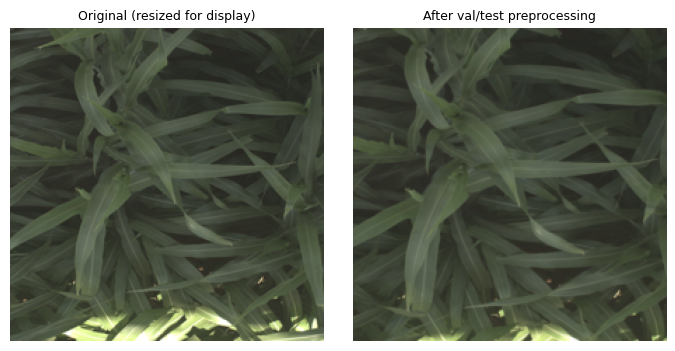

In [19]:
mean_t = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_t  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    return (t * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

val_tf = get_val_transform()
preprocessed = val_tf(orig_img)

print(f"Tensor shape : {tuple(preprocessed.shape)}")
print(f"Tensor dtype : {preprocessed.dtype}")
print(f"Pixel mean   : {preprocessed.mean():.4f}")
print(f"Pixel std    : {preprocessed.std():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(orig_img.resize((224, 224)))
axes[0].set_title("Original (resized for display)", fontsize=9)
axes[0].axis("off")
axes[1].imshow(denorm(preprocessed))
axes[1].set_title("After val/test preprocessing", fontsize=9)
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 5. Augmented Examples (train transform)

Each call to the training transform produces a different random augmentation.
This is intentional — augmentation varies per epoch during training.

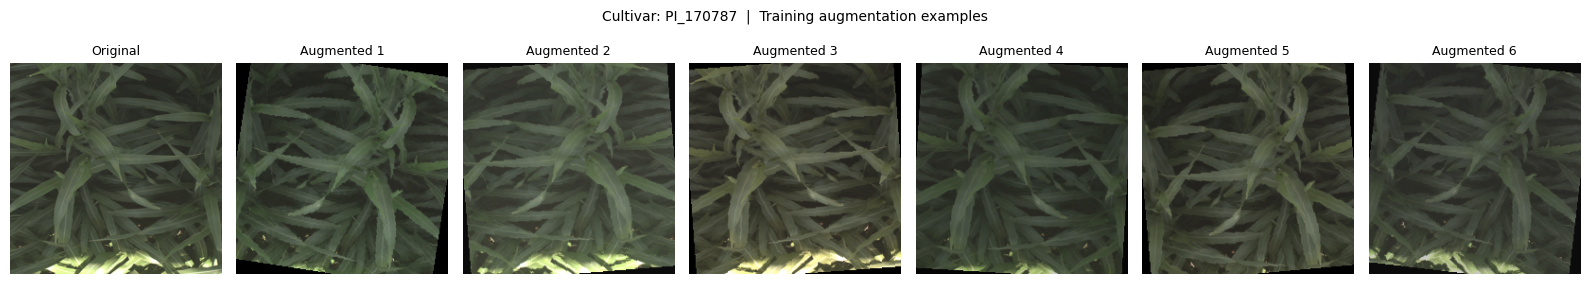

In [20]:
train_tf = get_train_transform()
N_AUG = 6

fig, axes = plt.subplots(1, N_AUG + 1, figsize=(16, 3))
axes[0].imshow(orig_img.resize((224, 224)))
axes[0].set_title("Original", fontsize=9)
axes[0].axis("off")

torch.manual_seed(SEED)
for i in range(N_AUG):
    axes[i + 1].imshow(denorm(train_tf(orig_img)))
    axes[i + 1].set_title(f"Augmented {i+1}", fontsize=9)
    axes[i + 1].axis("off")

fig.suptitle(
    f"Cultivar: {sample_row['cultivar']}  |  Training augmentation examples",
    fontsize=10,
)
plt.tight_layout()
plt.show()

## 6. Batch Sanity Checks

In [21]:
train_ds = SorghumDataset(train_df, IMAGE_DIR, get_train_transform(), class_to_idx)
val_ds   = SorghumDataset(val_df,   IMAGE_DIR, get_val_transform(),   class_to_idx)
test_ds  = SorghumDataset(test_df,  IMAGE_DIR, get_test_transform(),  class_to_idx)

train_loader = make_loader(train_ds, batch_size=32, shuffle=True,  seed=SEED)
val_loader   = make_loader(val_ds,   batch_size=32, shuffle=False, seed=SEED)
test_loader  = make_loader(test_ds,  batch_size=32, shuffle=False, seed=SEED)

def check_batch(loader, name):
    imgs, labels = next(iter(loader))
    assert imgs.ndim == 4
    assert imgs.shape[1] == 3
    assert imgs.shape[2] == IMAGE_SIZE
    assert imgs.shape[3] == IMAGE_SIZE
    assert imgs.dtype == torch.float32
    assert labels.dtype == torch.int64
    assert labels.min() >= 0
    assert labels.max() < len(class_to_idx)
    print(f"[OK] {name:10s}  shape={tuple(imgs.shape)}  "
          f"dtype={imgs.dtype}  labels=[{labels.min()}, {labels.max()}]  "
          f"pixel_mean={imgs.mean():.4f}  pixel_std={imgs.std():.4f}")

check_batch(train_loader, "train")
check_batch(val_loader,   "val")
check_batch(test_loader,  "test")

[OK] train       shape=(32, 3, 224, 224)  dtype=torch.float32  labels=[0, 86]  pixel_mean=-0.5613  pixel_std=0.8112
[OK] val         shape=(32, 3, 224, 224)  dtype=torch.float32  labels=[0, 99]  pixel_mean=-0.4166  pixel_std=0.8298
[OK] test        shape=(32, 3, 224, 224)  dtype=torch.float32  labels=[1, 97]  pixel_mean=-0.5745  pixel_std=0.7087


## 7. Determinism Check for Val/Test

In [22]:
imgs_v1, _ = next(iter(val_loader))
imgs_v2, _ = next(iter(val_loader))
assert torch.allclose(imgs_v1, imgs_v2), "val transform is NOT deterministic!"
print("[OK] val_transform produces identical tensors on repeated calls")

imgs_t1, _ = next(iter(test_loader))
imgs_t2, _ = next(iter(test_loader))
assert torch.allclose(imgs_t1, imgs_t2), "test transform is NOT deterministic!"
print("[OK] test_transform produces identical tensors on repeated calls")

print("\nAll preprocessing checks passed.")

[OK] val_transform produces identical tensors on repeated calls
[OK] test_transform produces identical tensors on repeated calls

All preprocessing checks passed.
